Currency Exchange Rate Tracker & Time Series Analysis
Built a data pipeline that pulls two years of daily exchange rates from a public API, stores them in a SQLite database, and analyzes trends with SQL window functions (moving averages, daily percentage change, monthly aggregates). Delivered cleaned dataset, charts, and full documentation.
Tools: Python, SQL, requests, pandas, matplotlib.

In [49]:
!pip install requests pandas matplotlib -q

import requests
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

print("Ready")

Ready


In [50]:
url = "https://api.frankfurter.dev/v1/latest?base=USD&symbols=EUR,GBP,JPY"

response = requests.get(url, timeout=10)
print("Status code:", response.status_code)

data = response.json()
print(data)

Status code: 200
{'amount': 1.0, 'base': 'USD', 'date': '2026-10-23', 'rates': {'EUR': 0.89342, 'GBP': 0.74804, 'JPY': 156.8}}


In [51]:
from datetime import date, timedelta

end_date = date.today()
start_date = end_date - timedelta(days=730)

symbols = "EUR,GBP,JPY,CHF,CAD,AUD"

url = f"https://api.frankfurter.dev/v1/{start_date}..{end_date}?base=USD&symbols={symbols}"

response = requests.get(url, timeout=30)
print("Status code:", response.status_code)

data = response.json()
print("Base:", data["base"])
print("Start:", data["start_date"])
print("End:", data["end_date"])
print("Days returned:", len(data["rates"]))

Status code: 200
Base: USD
Start: 2024-10-23
End: 2026-10-23
Days returned: 511


In [52]:
first_days = list(data["rates"].items())[:3]
for day, rates in first_days:
    print(day, rates)

2024-10-23 {'AUD': 1.5077, 'CAD': 1.3839, 'CHF': 0.86747, 'EUR': 0.92876, 'GBP': 0.77225, 'JPY': 152.93}
2024-10-24 {'AUD': 1.503, 'CAD': 1.3815, 'CHF': 0.86557, 'EUR': 0.92584, 'GBP': 0.77039, 'JPY': 151.95}
2024-10-25 {'AUD': 1.5068, 'CAD': 1.3847, 'CHF': 0.8667, 'EUR': 0.92379, 'GBP': 0.77005, 'JPY': 151.92}


In [53]:
rows = []
for day, rates in data["rates"].items():
    for currency, rate in rates.items():
        rows.append({"date": day, "currency": currency, "rate": rate})

df = pd.DataFrame(rows)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["currency", "date"]).reset_index(drop=True)

print(df.shape)
df.head(10)

(3066, 3)


,date,currency,rate
0,2024-10-23,AUD,1.5077
1,2024-10-24,AUD,1.5030
2,2024-10-25,AUD,1.5068
3,2024-10-28,AUD,1.5134
4,2024-10-29,AUD,1.5243
5,2024-10-30,AUD,1.5220
6,2024-10-31,AUD,1.5217
7,2024-11-01,AUD,1.5186
8,2024-11-04,AUD,1.5147
9,2024-11-05,AUD,1.5098


In [54]:
print("Shape:", df.shape)
print()
print(df.dtypes)
print()
print("Missing values:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated(subset=["date", "currency"]).sum())
print()
print("Rows per currency:")
print(df["currency"].value_counts())

Shape: (3066, 3)

date        datetime64[ns]
currency            object
rate               float64
dtype: object

Missing values:
date        0
currency    0
rate        0
dtype: int64

Duplicate rows: 0

Rows per currency:
currency
AUD    511
CAD    511
CHF    511
EUR    511
GBP    511
JPY    511
Name: count, dtype: int64


In [55]:
print(df.groupby("currency")["rate"].describe().round(4))

          count      mean     std       min       25%       50%       75%  \
currency                                                                    
AUD       511.0    1.4986  0.0704    1.3780    1.4268    1.5170    1.5483   
CAD       511.0    1.3949  0.0235    1.3524    1.3765    1.3905    1.4096   
CHF       511.0    0.8227  0.0403    0.7670    0.7957    0.8078    0.8336   
EUR       511.0    0.8828  0.0374    0.8351    0.8572    0.8662    0.8933   
GBP       511.0    0.7556  0.0211    0.7238    0.7415    0.7478    0.7621   
JPY       511.0  153.6150  5.4930  140.3400  148.6750  154.7500  158.0750   

               max  
currency            
AUD         1.6651  
CAD         1.4650  
CHF         0.9170  
EUR         0.9806  
GBP         0.8253  
JPY       163.9100  


In [56]:
df = df.drop_duplicates(subset=["date", "currency"])
df = df[df["rate"] > 0]

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["year_month"] = df["date"].dt.strftime("%Y-%m")
df["weekday"] = df["date"].dt.day_name()

df["date"] = df["date"].dt.strftime("%Y-%m-%d")
df = df.reset_index(drop=True)

print(df.shape)
df.head()

(3066, 7)


,date,currency,rate,year,month,year_month,weekday
0,2024-10-23,AUD,1.5077,2024,10,2024-10,Wednesday
1,2024-10-24,AUD,1.5030,2024,10,2024-10,Thursday
2,2024-10-25,AUD,1.5068,2024,10,2024-10,Friday
3,2024-10-28,AUD,1.5134,2024,10,2024-10,Monday
4,2024-10-29,AUD,1.5243,2024,10,2024-10,Tuesday


In [57]:
conn = sqlite3.connect("currency.db")

df.to_sql("rates", conn, if_exists="replace", index=False)

print(pd.read_sql("SELECT COUNT(*) AS total_rows FROM rates", conn))

   total_rows
0        3066


In [58]:
print(pd.read_sql("SELECT * FROM rates LIMIT 5", conn))

         date currency    rate  year  month year_month    weekday
0  2024-10-23      AUD  1.5077  2024     10    2024-10  Wednesday
1  2024-10-24      AUD  1.5030  2024     10    2024-10   Thursday
2  2024-10-25      AUD  1.5068  2024     10    2024-10     Friday
3  2024-10-28      AUD  1.5134  2024     10    2024-10     Monday
4  2024-10-29      AUD  1.5243  2024     10    2024-10    Tuesday


In [59]:
q1 = """
SELECT currency,
       MIN(rate) AS min_rate,
       MAX(rate) AS max_rate,
       ROUND(AVG(rate), 4) AS avg_rate
FROM rates
GROUP BY currency
ORDER BY currency
"""
print(pd.read_sql(q1, conn))

  currency   min_rate   max_rate  avg_rate
0      AUD    1.37800    1.66510    1.4986
1      CAD    1.35240    1.46500    1.3949
2      CHF    0.76703    0.91703    0.8227
3      EUR    0.83514    0.98058    0.8828
4      GBP    0.72376    0.82526    0.7556
5      JPY  140.34000  163.91000  153.6150


In [60]:
q2 = """
SELECT year_month,
       currency,
       ROUND(AVG(rate), 4) AS avg_rate
FROM rates
GROUP BY year_month, currency
ORDER BY currency, year_month
LIMIT 12
"""
print(pd.read_sql(q2, conn))

   year_month currency  avg_rate
0     2024-10      AUD    1.5141
1     2024-11      AUD    1.5304
2     2024-12      AUD    1.5775
3     2025-01      AUD    1.6058
4     2025-02      AUD    1.5874
5     2025-03      AUD    1.5878
6     2025-04      AUD    1.5916
7     2025-05      AUD    1.5536
8     2025-06      AUD    1.5390
9     2025-07      AUD    1.5298
10    2025-08      AUD    1.5407
11    2025-09      AUD    1.5168


In [40]:
q3 = """
SELECT currency, date, rate
FROM rates
WHERE date = (SELECT MAX(date) FROM rates)
ORDER BY currency
"""
print(pd.read_sql(q3, conn))

  currency        date       rate
0      AUD  2026-10-23    1.42400
1      CAD  2026-10-23    1.39950
2      CHF  2026-10-23    0.82435
3      EUR  2026-10-23    0.89342
4      GBP  2026-10-23    0.74804
5      JPY  2026-10-23  156.80000


In [41]:
q4 = """
SELECT weekday,
       ROUND(AVG(rate), 4) AS avg_eur_rate
FROM rates
WHERE currency = 'EUR'
GROUP BY weekday
ORDER BY avg_eur_rate DESC
"""
print(pd.read_sql(q4, conn))

     weekday  avg_eur_rate
0     Friday        0.8838
1   Thursday        0.8831
2     Monday        0.8830
3    Tuesday        0.8828
4  Wednesday        0.8815


In [42]:
q1 = """
SELECT date,
       currency,
       rate,
       LAG(rate) OVER (PARTITION BY currency ORDER BY date) AS prev_rate,
       ROUND(rate - LAG(rate) OVER (PARTITION BY currency ORDER BY date), 4) AS change
FROM rates
WHERE currency = 'EUR'
ORDER BY date
LIMIT 10
"""
print(pd.read_sql(q1, conn))

         date currency     rate  prev_rate  change
0  2024-10-23      EUR  0.92876        NaN     NaN
1  2024-10-24      EUR  0.92584    0.92876 -0.0029
2  2024-10-25      EUR  0.92379    0.92584 -0.0020
3  2024-10-28      EUR  0.92439    0.92379  0.0006
4  2024-10-29      EUR  0.92816    0.92439  0.0038
5  2024-10-30      EUR  0.92464    0.92816 -0.0035
6  2024-10-31      EUR  0.91895    0.92464 -0.0057
7  2024-11-01      EUR  0.91870    0.91895 -0.0003
8  2024-11-04      EUR  0.91709    0.91870 -0.0016
9  2024-11-05      EUR  0.91768    0.91709  0.0006


In [43]:
q2 = """
SELECT date,
       currency,
       rate,
       ROUND(
           (rate - LAG(rate) OVER (PARTITION BY currency ORDER BY date))
           * 100.0
           / LAG(rate) OVER (PARTITION BY currency ORDER BY date),
           3
       ) AS daily_change_pct
FROM rates
WHERE currency = 'EUR'
ORDER BY date
LIMIT 10
"""
print(pd.read_sql(q2, conn))

         date currency     rate  daily_change_pct
0  2024-10-23      EUR  0.92876               NaN
1  2024-10-24      EUR  0.92584            -0.314
2  2024-10-25      EUR  0.92379            -0.221
3  2024-10-28      EUR  0.92439             0.065
4  2024-10-29      EUR  0.92816             0.408
5  2024-10-30      EUR  0.92464            -0.379
6  2024-10-31      EUR  0.91895            -0.615
7  2024-11-01      EUR  0.91870            -0.027
8  2024-11-04      EUR  0.91709            -0.175
9  2024-11-05      EUR  0.91768             0.064


In [44]:
q3 = """
SELECT date,
       currency,
       rate,
       ROUND(AVG(rate) OVER (
           PARTITION BY currency
           ORDER BY date
           ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
       ), 4) AS ma_7,
       ROUND(AVG(rate) OVER (
           PARTITION BY currency
           ORDER BY date
           ROWS BETWEEN 29 PRECEDING AND CURRENT ROW
       ), 4) AS ma_30
FROM rates
WHERE currency = 'EUR'
ORDER BY date DESC
LIMIT 10
"""
print(pd.read_sql(q3, conn))

         date currency     rate    ma_7   ma_30
0  2026-10-23      EUR  0.89342  0.8913  0.8839
1  2026-10-22      EUR  0.89246  0.8913  0.8829
2  2026-10-21      EUR  0.89015  0.8915  0.8818
3  2026-10-20      EUR  0.89166  0.8921  0.8807
4  2026-10-19      EUR  0.89087  0.8922  0.8797
5  2026-10-16      EUR  0.88865  0.8927  0.8787
6  2026-10-15      EUR  0.89222  0.8935  0.8778
7  2026-10-14      EUR  0.89326  0.8928  0.8767
8  2026-10-13      EUR  0.89381  0.8927  0.8757
9  2026-10-12      EUR  0.89437  0.8923  0.8747


In [45]:
q4 = """
WITH changes AS (
    SELECT date,
           currency,
           rate,
           (rate - LAG(rate) OVER (PARTITION BY currency ORDER BY date))
           * 100.0
           / LAG(rate) OVER (PARTITION BY currency ORDER BY date) AS daily_change_pct
    FROM rates
)
SELECT date,
       currency,
       ROUND(daily_change_pct, 3) AS daily_change_pct
FROM changes
WHERE daily_change_pct IS NOT NULL
ORDER BY ABS(daily_change_pct) DESC
LIMIT 10
"""
print(pd.read_sql(q4, conn))

         date currency  daily_change_pct
0  2025-04-04      AUD             4.102
1  2025-04-10      AUD            -2.967
2  2025-04-11      CHF            -2.821
3  2025-04-03      CHF            -2.701
4  2025-04-03      EUR            -2.650
5  2026-01-26      JPY            -2.497
6  2025-04-11      EUR            -2.326
7  2026-09-03      JPY            -2.249
8  2026-08-03      JPY            -2.222
9  2025-04-03      JPY            -2.077


In [46]:
q5 = """
WITH changes AS (
    SELECT currency,
           (rate - LAG(rate) OVER (PARTITION BY currency ORDER BY date))
           * 100.0
           / LAG(rate) OVER (PARTITION BY currency ORDER BY date) AS daily_change_pct
    FROM rates
)
SELECT currency,
       ROUND(AVG(ABS(daily_change_pct)), 3) AS avg_abs_change_pct,
       ROUND(MAX(daily_change_pct), 3) AS max_rise_pct,
       ROUND(MIN(daily_change_pct), 3) AS max_drop_pct
FROM changes
WHERE daily_change_pct IS NOT NULL
GROUP BY currency
ORDER BY avg_abs_change_pct DESC
"""
print(pd.read_sql(q5, conn))

  currency  avg_abs_change_pct  max_rise_pct  max_drop_pct
0      AUD               0.419         4.102        -2.967
1      JPY               0.410         1.998        -2.497
2      CHF               0.339         1.519        -2.821
3      GBP               0.323         1.634        -1.824
4      EUR               0.314         1.890        -2.650
5      CAD               0.232         1.272        -1.661


In [73]:
q6 = """
WITH bounds AS (
    SELECT currency,
           MIN(date) AS first_date,
           MAX(date) AS last_date
    FROM rates
    GROUP BY currency
)
SELECT b.currency,
       f.rate AS first_rate,
       l.rate AS last_rate,
       ROUND((l.rate - f.rate) * 100.0 / f.rate, 2) AS total_change_pct
FROM bounds b
JOIN rates f ON f.currency = b.currency AND f.date = b.first_date
JOIN rates l ON l.currency = b.currency AND l.date = b.last_date
ORDER BY total_change_pct DESC
"""
print(pd.read_sql(q6, conn))

  currency  first_rate  last_rate  total_change_pct
0      JPY   152.93000  156.80000              2.53
1      CAD     1.38390    1.39950              1.13
2      GBP     0.77225    0.74804             -3.13
3      EUR     0.92876    0.89342             -3.81
4      CHF     0.86747    0.82435             -4.97
5      AUD     1.50770    1.42400             -5.55


In [74]:
q = """
SELECT date, rate,
       AVG(rate) OVER (ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW) AS ma_7,
       AVG(rate) OVER (ORDER BY date ROWS BETWEEN 29 PRECEDING AND CURRENT ROW) AS ma_30
FROM rates
WHERE currency = 'EUR'
ORDER BY date
"""
eur = pd.read_sql(q, conn)
eur["date"] = pd.to_datetime(eur["date"])
print(eur.shape)

(511, 4)


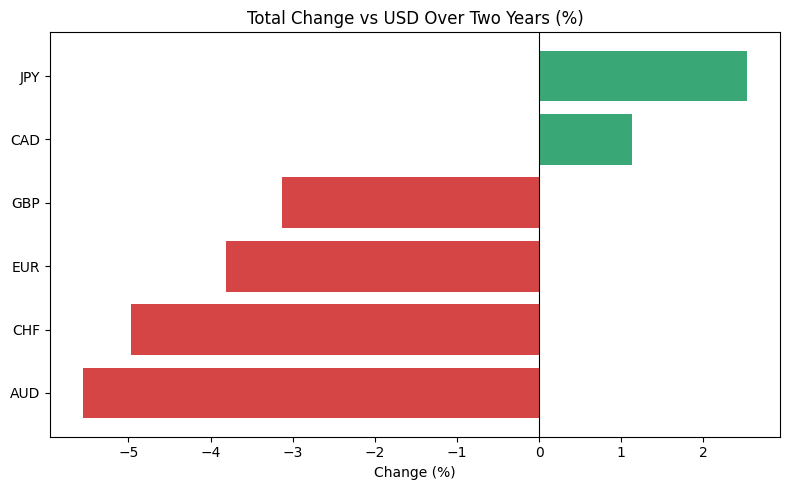

In [68]:
q = """
WITH bounds AS (
    SELECT currency, MIN(date) AS first_date, MAX(date) AS last_date
    FROM rates
    GROUP BY currency
)
SELECT b.currency,
       ROUND((l.rate - f.rate) * 100.0 / f.rate, 2) AS total_change_pct
FROM bounds b
JOIN rates f ON f.currency = b.currency AND f.date = b.first_date
JOIN rates l ON l.currency = b.currency AND l.date = b.last_date
ORDER BY total_change_pct
"""
total = pd.read_sql(q, conn)
colors = ["#d64545" if v < 0 else "#3aa876" for v in total["total_change_pct"]]

plt.figure(figsize=(8, 5))
plt.barh(total["currency"], total["total_change_pct"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Total Change vs USD Over Two Years (%)")
plt.xlabel("Change (%)")
plt.tight_layout()
plt.savefig("total_change.png", dpi=150)
plt.show()

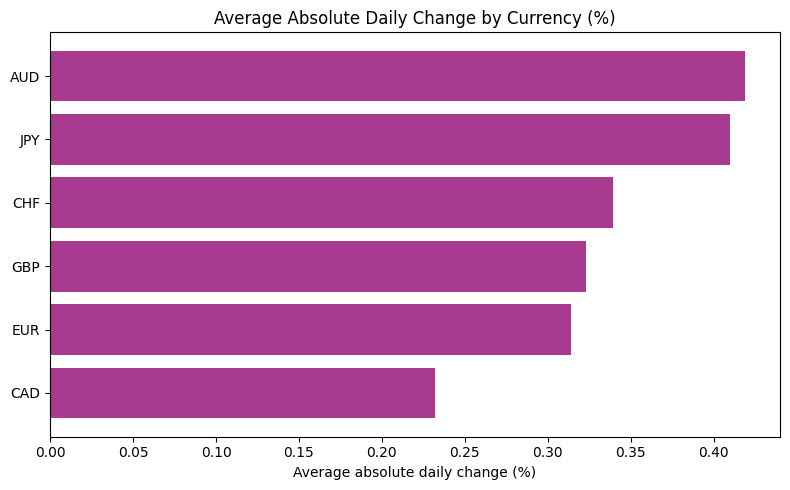

In [69]:
q = """
WITH changes AS (
    SELECT currency,
           (rate - LAG(rate) OVER (PARTITION BY currency ORDER BY date))
           * 100.0
           / LAG(rate) OVER (PARTITION BY currency ORDER BY date) AS daily_change_pct
    FROM rates
)
SELECT currency,
       ROUND(AVG(ABS(daily_change_pct)), 3) AS avg_abs_change_pct
FROM changes
WHERE daily_change_pct IS NOT NULL
GROUP BY currency
ORDER BY avg_abs_change_pct
"""
vol = pd.read_sql(q, conn)

plt.figure(figsize=(8, 5))
plt.barh(vol["currency"], vol["avg_abs_change_pct"], color="#a83a8f")
plt.title("Average Absolute Daily Change by Currency (%)")
plt.xlabel("Average absolute daily change (%)")
plt.tight_layout()
plt.savefig("volatility.png", dpi=150)
plt.show()

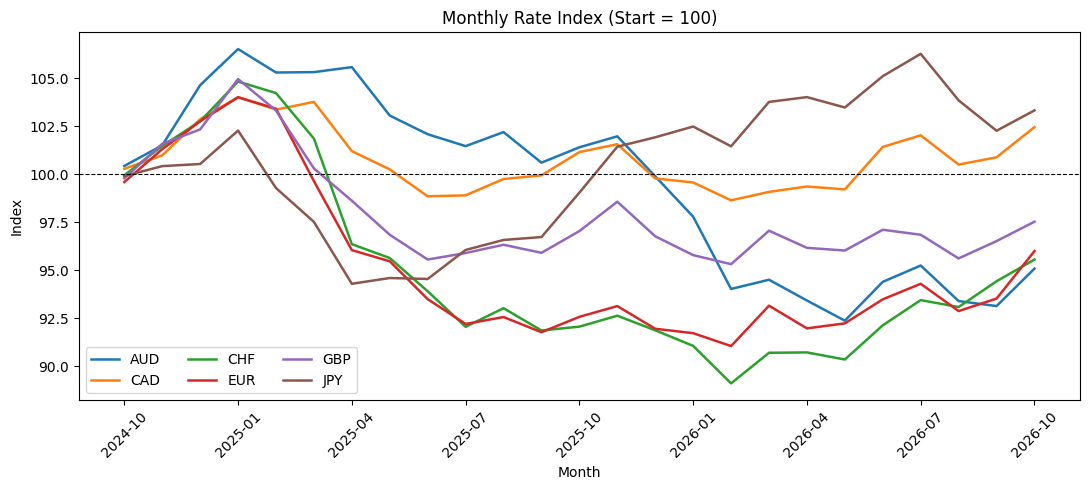

In [70]:
q = """
WITH base AS (
    SELECT currency, MIN(date) AS first_date
    FROM rates
    GROUP BY currency
),
indexed AS (
    SELECT r.year_month,
           r.currency,
           AVG(r.rate * 100.0 / f.rate) AS idx
    FROM rates r
    JOIN base b ON r.currency = b.currency
    JOIN rates f ON f.currency = b.currency AND f.date = b.first_date
    GROUP BY r.year_month, r.currency
)
SELECT year_month, currency, ROUND(idx, 2) AS idx
FROM indexed
ORDER BY year_month
"""
idx = pd.read_sql(q, conn)
pivot = idx.pivot(index="year_month", columns="currency", values="idx")

plt.figure(figsize=(11, 5))
for c in pivot.columns:
    plt.plot(pivot.index, pivot[c], label=c, linewidth=1.8)
plt.axhline(100, color="black", linewidth=0.8, linestyle="--")
plt.title("Monthly Rate Index (Start = 100)")
plt.xlabel("Month")
plt.ylabel("Index")
plt.xticks(pivot.index[::3], rotation=45)
plt.legend(ncol=3)
plt.tight_layout()
plt.savefig("monthly_index.png", dpi=150)
plt.show()

In [72]:
import os
print(sorted(f for f in os.listdir(".") if f.endswith((".png", ".csv", ".db"))))

['currency.db', 'exchange_rates_final.csv', 'monthly_index.png', 'total_change.png', 'volatility.png']


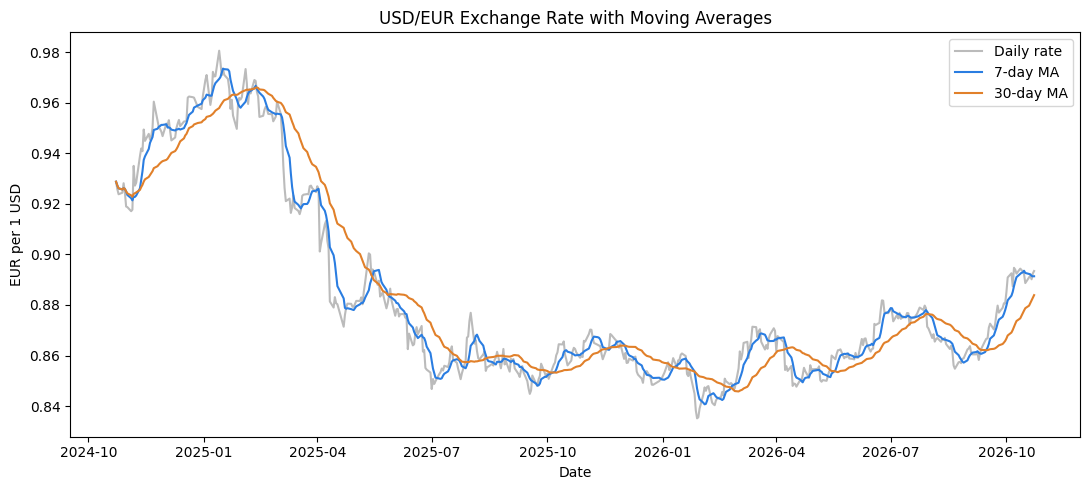

In [75]:
plt.figure(figsize=(11, 5))
plt.plot(eur["date"], eur["rate"], label="Daily rate", color="#bbbbbb")
plt.plot(eur["date"], eur["ma_7"], label="7-day MA", color="#2a7de1")
plt.plot(eur["date"], eur["ma_30"], label="30-day MA", color="#e1802a")
plt.title("USD/EUR Exchange Rate with Moving Averages")
plt.xlabel("Date")
plt.ylabel("EUR per 1 USD")
plt.legend()
plt.tight_layout()
plt.savefig("eur_moving_averages.png", dpi=150)
plt.show()

In [76]:
import os
from google.colab import files

names = ["exchange_rates_final.csv", "currency.db", "eur_moving_averages.png", "total_change.png", "volatility.png", "monthly_index.png"]

for f in names:
    if os.path.exists(f):
        files.download(f)
    else:
        print("Missing:", f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [77]:
total = pd.read_sql("SELECT COUNT(*) AS n, MIN(date) AS start_date, MAX(date) AS end_date FROM rates", conn).iloc[0]
print(total)

n                   3066
start_date    2024-10-23
end_date      2026-10-23
Name: 0, dtype: object


In [78]:
vol = pd.read_sql("""
WITH changes AS (
    SELECT currency,
           (rate - LAG(rate) OVER (PARTITION BY currency ORDER BY date)) * 100.0
           / LAG(rate) OVER (PARTITION BY currency ORDER BY date) AS pct
    FROM rates
)
SELECT currency, ROUND(AVG(ABS(pct)), 3) AS avg_abs_pct
FROM changes
WHERE pct IS NOT NULL
GROUP BY currency
ORDER BY avg_abs_pct DESC
""", conn)
print(vol)

  currency  avg_abs_pct
0      AUD        0.419
1      JPY        0.410
2      CHF        0.339
3      GBP        0.323
4      EUR        0.314
5      CAD        0.232


In [79]:
chg = pd.read_sql("""
WITH bounds AS (
    SELECT currency, MIN(date) AS d1, MAX(date) AS d2
    FROM rates
    GROUP BY currency
)
SELECT b.currency,
       ROUND((l.rate - f.rate) * 100.0 / f.rate, 2) AS total_pct
FROM bounds b
JOIN rates f ON f.currency = b.currency AND f.date = b.d1
JOIN rates l ON l.currency = b.currency AND l.date = b.d2
ORDER BY total_pct DESC
""", conn)
print(chg)

  currency  total_pct
0      JPY       2.53
1      CAD       1.13
2      GBP      -3.13
3      EUR      -3.81
4      CHF      -4.97
5      AUD      -5.55


In [80]:
most_vol = vol.iloc[0]
least_vol = vol.iloc[-1]
top_move = chg.iloc[0]
low_move = chg.iloc[-1]

findings = f"""- The dataset covers {int(total['n'])} daily observations from {total['start_date']} to {total['end_date']} across {len(vol)} currencies.
- The most volatile currency against USD is {most_vol['currency']} (average absolute daily change {most_vol['avg_abs_pct']}%), while the most stable is {least_vol['currency']} ({least_vol['avg_abs_pct']}%).
- Over the full period, the USD gained the most against {top_move['currency']} ({top_move['total_pct']}%) and gained the least or lost the most against {low_move['currency']} ({low_move['total_pct']}%).
- Moving averages (7-day and 30-day) were computed with SQL window functions to separate short-term noise from trend."""
print(findings)

- The dataset covers 3066 daily observations from 2024-10-23 to 2026-10-23 across 6 currencies.
- The most volatile currency against USD is AUD (average absolute daily change 0.419%), while the most stable is CAD (0.232%).
- Over the full period, the USD gained the most against JPY (2.53%) and gained the least or lost the most against AUD (-5.55%).
- Moving averages (7-day and 30-day) were computed with SQL window functions to separate short-term noise from trend.


In [81]:
readme = f"""# Currency Exchange Rate Tracker & Time Series Analysis

A data pipeline that pulls daily exchange rates from a public API, stores them in SQLite, and analyzes trends with SQL window functions.

## Data Source
Frankfurter API (European Central Bank reference rates), base currency USD.

## Tools
- Python: requests, pandas, matplotlib
- SQL: SQLite (LAG, moving averages, CTEs, joins, aggregation)
- Google Colab

## Pipeline
1. Pulled two years of daily rates for 6 currencies (EUR, GBP, JPY, CHF, CAD, AUD)
2. Reshaped the JSON response into a long-format table
3. Cleaned the data and added year, month, and weekday columns
4. Stored the data in SQLite
5. Ran SQL analysis: min/max, monthly averages, daily change, 7 and 30 day moving averages, volatility ranking
6. Visualized results with matplotlib

## Key Findings
{findings}

## Files
- exchange_rates_final.csv: cleaned dataset
- currency.db: SQLite database
- *.png: charts

## How to Run
Open the notebook in Google Colab and run all cells in order.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

from google.colab import files
files.download("README.md")
print("Done")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done
